# 02 — CLIP Image-to-Image Retrieval Baseline

## Purpose of this notebook

This notebook moves from **representation** to **retrieval**. Notebook 01 created one normalized CLIP image embedding for every architectural image. Here, those fixed embeddings are used to ask a practical question:

> **Given one architectural image as a query, which other images does CLIP consider most similar?**


### Important interpretation

CLIP is **not predicting an architectural-style label** in this notebook. For a query image, it searches the embedding collection and retrieves neighboring **images**. We then inspect the dataset labels attached to those images. Consequently, a retrieved image with a different style label is a *label mismatch in retrieval evaluation*, not a direct classification error made by CLIP.

The notebook progresses through four stages:

1. Load the metadata and precomputed CLIP embeddings.
2. Implement nearest-neighbor image retrieval using cosine similarity.
3. Inspect retrievals visually for individual query images.
4. Quantify exact-label retrieval performance with Precision@K over the full dataset.

This baseline later provides the reference point for asking whether nominally different-label retrievals may nevertheless be architecturally meaningful.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

metadata = pd.read_csv("architecture_metadata.csv")
embeddings = np.load("clip_image_embeddings.npy")

print("Metadata:", metadata.shape)
print("Embeddings:", embeddings.shape)

Metadata: (10113, 3)
Embeddings: (10113, 512)


## Data-integrity check: metadata and embeddings must remain aligned

Each row of `metadata` must refer to the same image as the embedding at the identical row/index position in `embeddings`. The retrieval code relies on this positional correspondence.

For example, if row 5000 of the metadata describes an American Foursquare image, `embeddings[5000]` must be the CLIP vector produced from that exact image. A mismatch between these two arrays would silently corrupt every retrieval result.

The assertion below therefore checks the most basic alignment condition before any similarity calculation is attempted. It does not prove that every filepath and embedding is semantically correct, but it catches a fundamental length mismatch immediately.


In [2]:
assert len(metadata) == len(embeddings)

print("Everything aligned!")

Everything aligned!


## Define CLIP nearest-neighbor retrieval

The function below performs **image-to-image retrieval in CLIP embedding space**.

For a selected `query_id`, it:

1. takes the stored CLIP embedding for the query image;
2. compares it with every embedding in the dataset;
3. excludes the query image itself so that an image cannot trivially retrieve itself;
4. ranks the remaining images from highest to lowest similarity;
5. returns the top `k` metadata rows together with their similarity scores.

Because the embeddings created in Notebook 01 are normalized, their dot product is equivalent to **cosine similarity**. Higher values therefore indicate that CLIP places the two images closer together in its learned representation space.

### What the similarity score means

The CLIP similarity is an **image-level learned similarity**. It should not be interpreted as an explicit architectural-style similarity score. CLIP may respond to combinations of form, visual composition, façade structure, materials, ornament, windows, roof geometry, photographic context, and other learned visual cues.

In [3]:
def retrieve_similar_images(query_id, top_k=8):
    # Embedding of the query image
    query_embedding = embeddings[query_id]

    # Cosine similarity with every image
    similarities = embeddings @ query_embedding

    # Sort from most to least similar
    ranked_indices = np.argsort(similarities)[::-1]

    # Remove the query image itself
    ranked_indices = ranked_indices[ranked_indices != query_id]

    # Keep the top K
    top_indices = ranked_indices[:top_k]

    results = metadata.iloc[top_indices].copy()
    results["similarity"] = similarities[top_indices]

    return results

## First retrieval example: inspect the ranked neighbors numerically

A fixed query ID is used here so that the example is reproducible. Running the notebook again with the same data will examine the same query image.

The output reports the query's metadata and the top retrieved images. At this stage, the goal is descriptive: verify that the retrieval function produces sensible neighbors and inspect whether the retrieved style labels agree with the query label.

A same-label result is counted as relevant under the conventional exact-label evaluation used later. A different-label result is not automatically evidence of visual or architectural irrelevance; it simply fails the exact-label criterion.


In [4]:
QUERY_ID = 5000

print("QUERY")
print(metadata.iloc[QUERY_ID][["image_id", "style"]])

results = retrieve_similar_images(QUERY_ID, top_k=8)

results[["image_id", "style", "similarity"]]

QUERY
image_id                5000
style       Deconstructivism
Name: 5000, dtype: object


,image_id,style,similarity
4971,4971,Deconstructivism,0.972160
5076,5076,Deconstructivism,0.952654
5014,5014,Deconstructivism,0.942465
4979,4979,Deconstructivism,0.937807
4977,4977,Deconstructivism,0.937335
5028,5028,Deconstructivism,0.926184
4972,4972,Deconstructivism,0.923673
5117,5117,Deconstructivism,0.889193


## Visualize the query and its top retrieved images

Numerical similarity values alone do not reveal *why* CLIP placed two architectural images near each other. This visualization places the query beside its highest-ranked neighbors so that retrieval quality can be inspected directly.

This qualitative check is useful for detecting obvious implementation problems—for example, unrelated images, corrupted paths, or retrievals dominated by unexpected photographic artifacts. It also illustrates an important motivation for the later graded-relevance analysis: two buildings can appear architecturally related even when their dataset style labels differ.

The visualization is exploratory evidence rather than the quantitative evaluation itself.


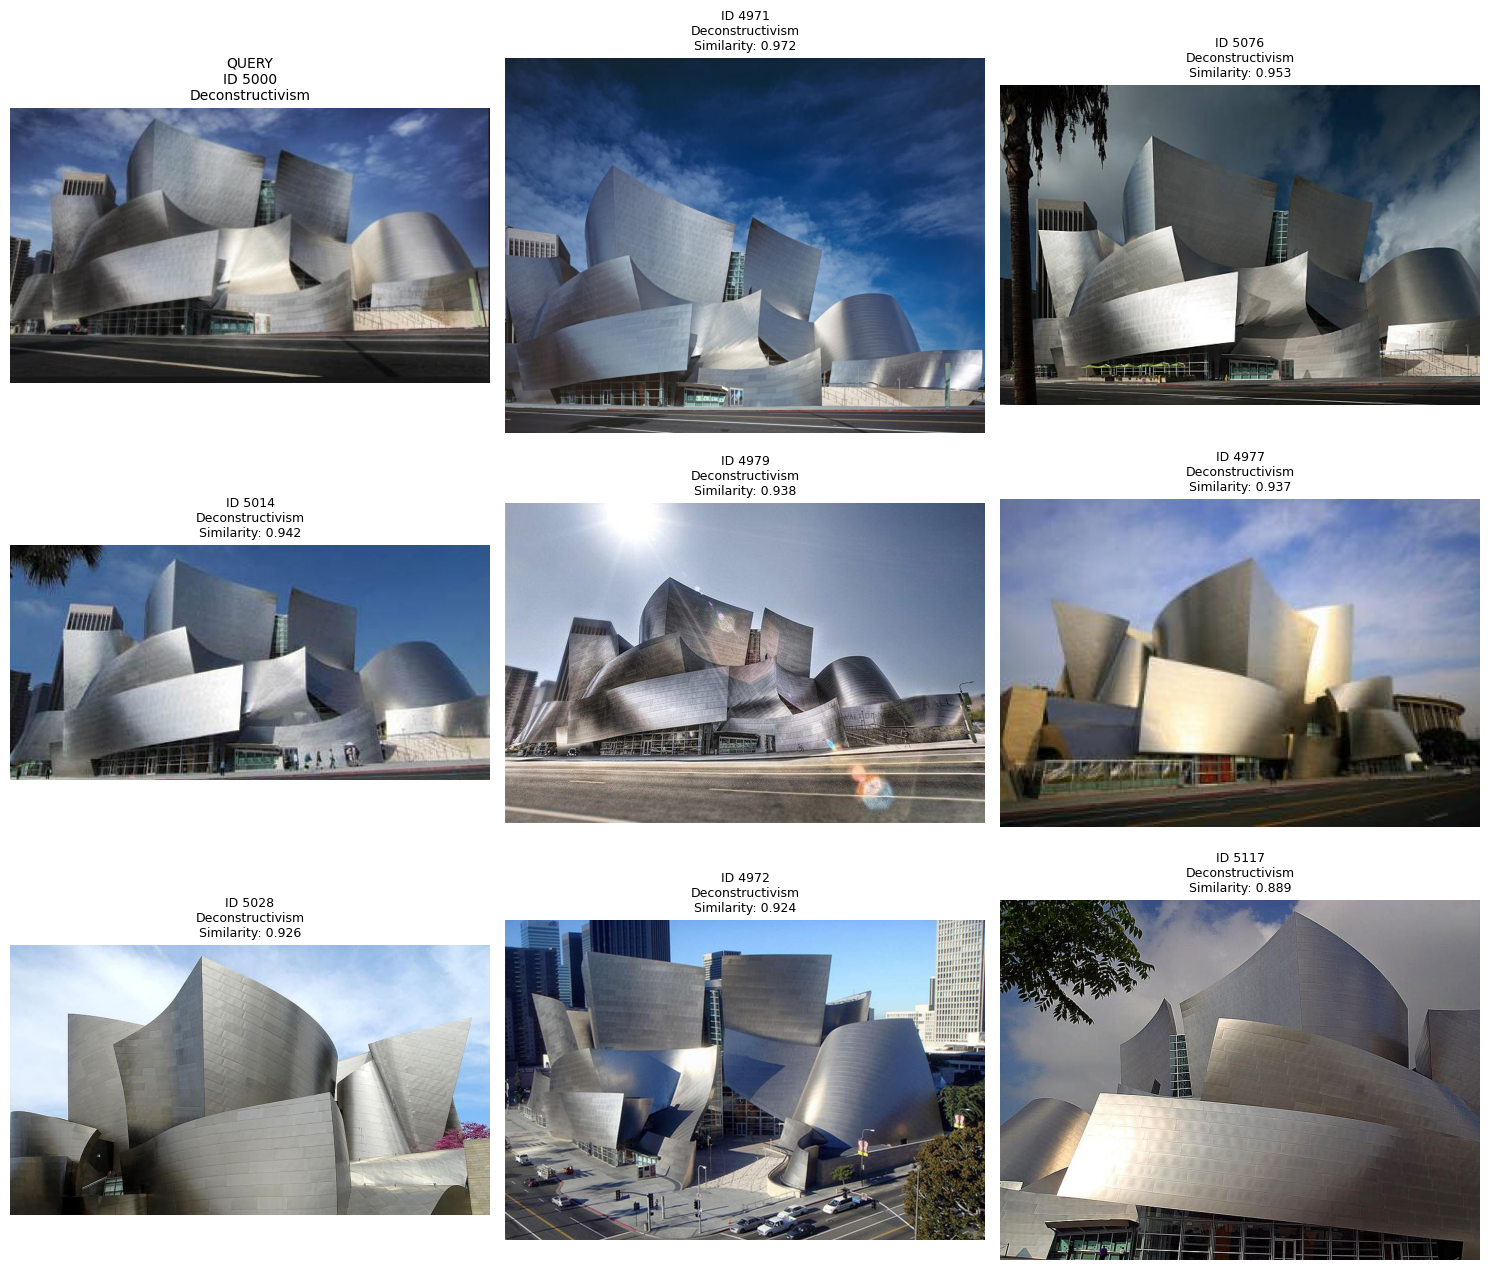

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13))

# Query image
query_row = metadata.iloc[QUERY_ID]
query_img = Image.open(query_row["image_path"]).convert("RGB")

axes[0, 0].imshow(query_img)
axes[0, 0].set_title(
    f"QUERY\nID {QUERY_ID}\n{query_row['style']}",
    fontsize=10
)
axes[0, 0].axis("off")

# Retrieved images
for ax, (_, row) in zip(axes.flat[1:], results.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")
    
    ax.imshow(img)
    ax.set_title(
        f"ID {row['image_id']}\n"
        f"{row['style']}\n"
        f"Similarity: {row['similarity']:.3f}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

## Select a reproducible random query

A single hand-selected example can unintentionally present an unusually good or unusually bad retrieval. This cell therefore selects a query using a fixed random seed.

`random_state=123` makes the selection reproducible: although the query is sampled, the same image will be chosen whenever the cell is rerun on the same metadata table.

This gives us another qualitative retrieval example without manually choosing a style or image that supports a desired narrative.


In [6]:
# Pick one reproducible random image
query_row = metadata.sample(n=1, random_state=123).iloc[0]
QUERY_ID = int(query_row["image_id"])

print("Query ID:", QUERY_ID)
print("Style:", query_row["style"])

results = retrieve_similar_images(QUERY_ID, top_k=8)

results[["image_id", "style", "similarity"]]

Query ID: 3567
Style: Beaux-Arts architecture


,image_id,style,similarity
5750,5750,Georgian architecture,0.897264
3511,3511,Beaux-Arts architecture,0.883174
4773,4773,Colonial architecture,0.877802
5755,5755,Georgian architecture,0.875157
7666,7666,Palladian architecture,0.874960
7795,7795,Palladian architecture,0.874912
4699,4699,Colonial architecture,0.873057
7739,7739,Palladian architecture,0.869661


## Package the retrieval visualization into a reusable function

The previous visualization is converted into `show_retrieval()` so that arbitrary query images can be inspected consistently.

Keeping the display logic in one function reduces duplicated plotting code and ensures that different qualitative examples use the same presentation. The query remains visually distinguished from the retrieved neighbors, while each retrieved image can be annotated with its style and CLIP similarity.

This function does not change retrieval rankings or calculate a new metric; it is purely a visualization utility.


In [7]:
def show_retrieval(query_id, results):
    fig, axes = plt.subplots(3, 3, figsize=(15, 13))

    query_row = metadata.iloc[query_id]
    query_img = Image.open(query_row["image_path"]).convert("RGB")

    axes[0, 0].imshow(query_img)
    axes[0, 0].set_title(
        f"QUERY\nID {query_id}\n{query_row['style']}",
        fontsize=10
    )
    axes[0, 0].axis("off")

    for ax, (_, row) in zip(axes.flat[1:], results.iterrows()):
        img = Image.open(row["image_path"]).convert("RGB")

        ax.imshow(img)
        ax.set_title(
            f"ID {row['image_id']}\n"
            f"{row['style']}\n"
            f"Similarity: {row['similarity']:.3f}",
            fontsize=9
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## Display the reproducibly sampled retrieval example

This cell applies the reusable visualization function to the current query and its retrieval results.

The purpose remains qualitative inspection: look for visual coherence, same-style neighbors, and plausible cross-style neighbors. These examples can later help select representative figures for the paper, but formal conclusions should come from the full-dataset quantitative evaluation below.


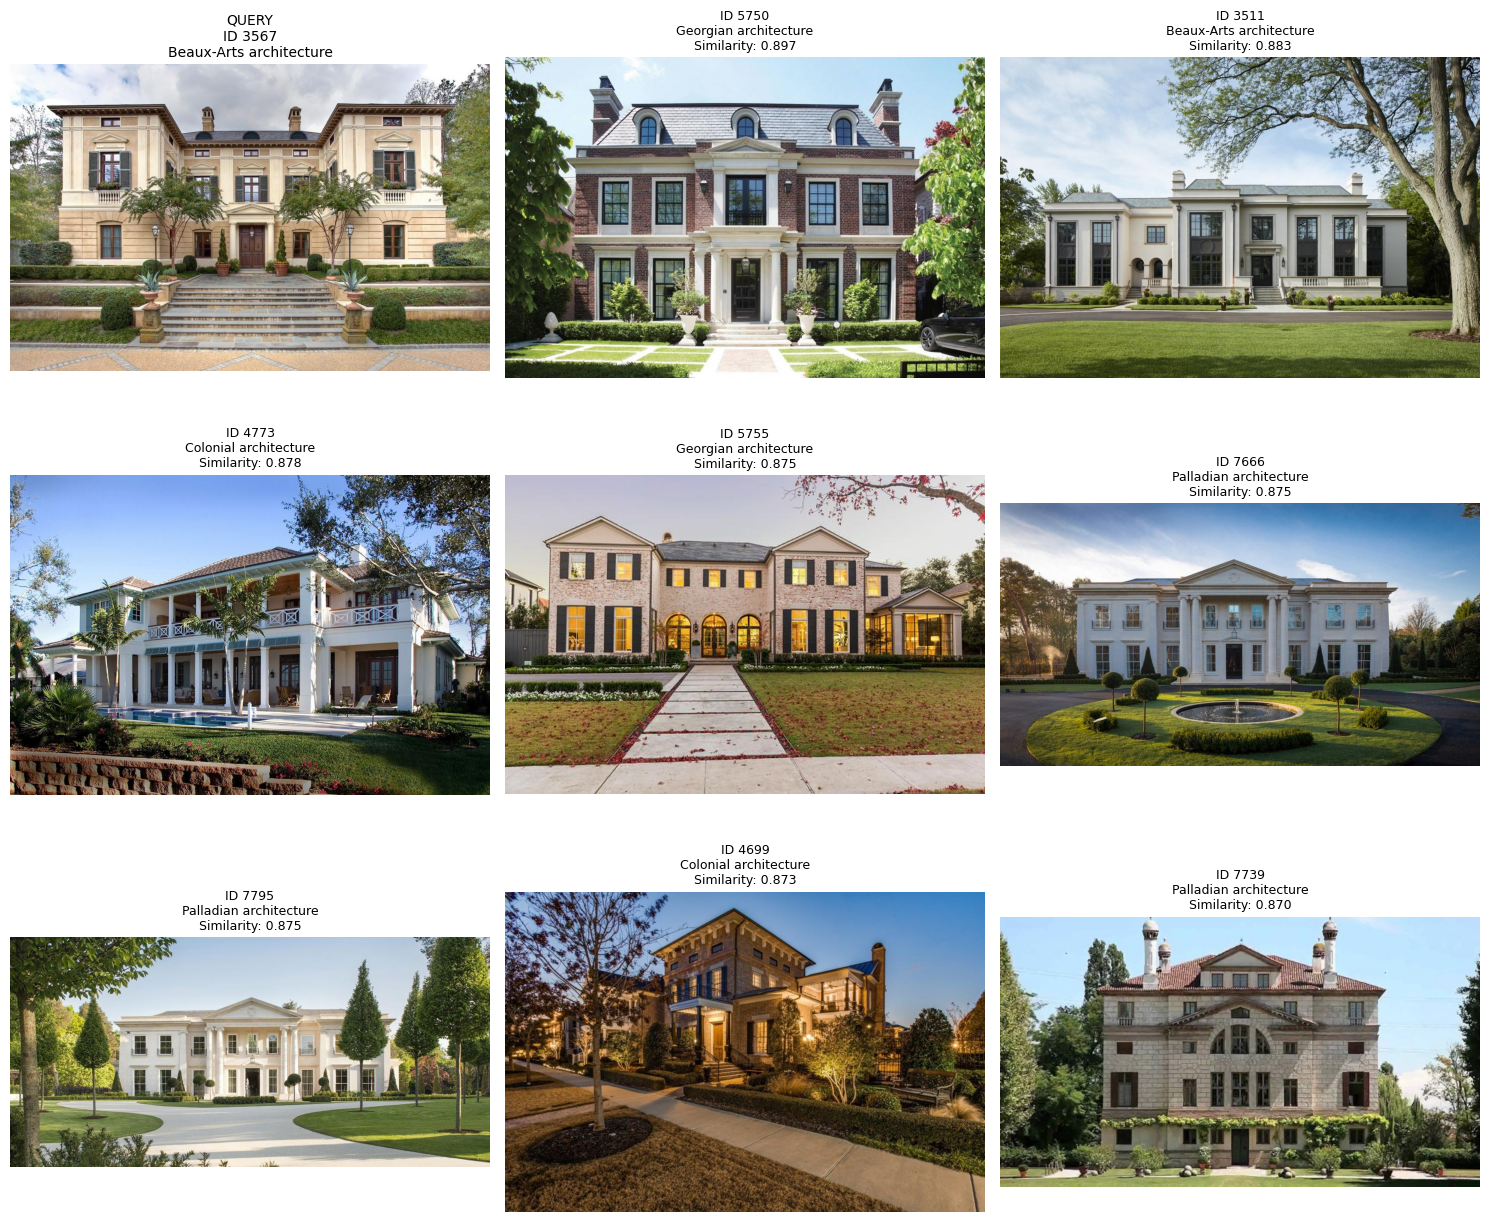

In [8]:
show_retrieval(QUERY_ID, results)

# Conventional exact-label retrieval metric: Precision@K

We now move from individual examples to a quantitative metric.

For a query image, **Precision@K (P@K)** asks what fraction of the top `K` retrieved images have the **same dataset architectural-style label** as the query.

For example, if 4 of the top 5 retrieved images share the query's label:

\[
P@5 = \frac{4}{5} = 0.8
\]

### Why use exact labels here?

Exact-label P@K provides a simple, reproducible baseline that is easy to compare across experiments. It deliberately uses a strict binary definition of relevance:

- same style label → relevant;
- different style label → not relevant.

This definition is useful but incomplete for the practical architectural-search problem. A Georgian query retrieving a Greek Revival image, for example, receives zero credit under exact-label evaluation even if the buildings share meaningful architectural properties.

That limitation is not corrected in this cell. It is preserved deliberately so that Paper One can first establish the conventional CLIP baseline and then investigate what information may be hidden inside its apparent cross-label errors.


In [9]:
def precision_at_k(query_id, k):
    # Get the query embedding and its architectural style
    query_embedding = embeddings[query_id]
    query_style = metadata.iloc[query_id]["style"]

    # Similarity between query and every image
    similarities = embeddings @ query_embedding

    # Rank from highest similarity to lowest
    ranked_indices = np.argsort(similarities)[::-1]

    # Remove the query image itself
    ranked_indices = ranked_indices[ranked_indices != query_id]

    # Keep only the top k
    top_indices = ranked_indices[:k]

    # Get their architectural styles
    retrieved_styles = metadata.iloc[top_indices]["style"]

    # Count how many have the same style as the query
    relevant = (retrieved_styles == query_style).sum()

    return relevant / k

## Inspect P@1, P@5, and P@10 for one query

Before computing dataset-wide metrics, this cell applies the exact-label Precision@K function to one fixed query.

The three values answer increasingly broad neighborhood questions:

- **P@1**: Does CLIP's single nearest non-self image have the same style label?
- **P@5**: What fraction of the five nearest images have the same label?
- **P@10**: What fraction of the ten nearest images have the same label?

A single query is only a sanity check and should not be treated as the overall performance estimate.


In [10]:
QUERY_ID = 3567

print("Style:", metadata.iloc[QUERY_ID]["style"])
print("P@1 :", precision_at_k(QUERY_ID, 1))
print("P@5 :", precision_at_k(QUERY_ID, 5))
print("P@10:", precision_at_k(QUERY_ID, 10))

Style: Beaux-Arts architecture
P@1 : 0.0
P@5 : 0.2
P@10: 0.2


# Full-dataset CLIP retrieval evaluation

The function below computes mean Precision@K over **every image in the dataset**, making each image a query in turn.

For each batch of query embeddings, the function:

1. computes similarities between the query batch and the complete embedding matrix;
2. suppresses each query's self-match by setting its self-similarity to negative infinity;
3. ranks all candidate images by similarity;
4. checks the style labels of the top `K` retrieved images;
5. records the fraction whose label exactly matches the query label;
6. averages those per-query precision values over the entire dataset.

### Why process queries in batches?

A full all-versus-all similarity calculation can require substantial memory. Processing query images in batches retains the same retrieval logic while limiting the size of the temporary similarity matrix.

### Interpretation of the final values

The resulting P@1, P@5, and P@10 are **strict exact-label retrieval metrics**. They quantify how well CLIP's embedding neighborhoods preserve the dataset's architectural-style categories.

They do *not* yet answer whether different-label neighbors are architecturally reasonable. That question is intentionally deferred to the architectural-similarity analysis, where the binary label criterion is examined more critically.


In [11]:
def evaluate_precision_at_k(embeddings, metadata, ks=(1, 5, 10), batch_size=256):
    
    n = len(embeddings)
    styles = metadata["style"].to_numpy()

    # Store the precision for every query
    precision_scores = {k: [] for k in ks}

    for start in range(0, n, batch_size):
        end = min(start + batch_size, n)

        # Embeddings for this batch of query images
        query_batch = embeddings[start:end]

        # Compare every query in the batch with every image
        similarities = query_batch @ embeddings.T

        # Prevent each query from retrieving itself
        rows = np.arange(end - start)
        cols = np.arange(start, end)
        similarities[rows, cols] = -np.inf

        # Rank the images for each query
        ranked_indices = np.argsort(similarities, axis=1)[:, ::-1]

        # Calculate Precision@K
        for i, query_id in enumerate(range(start, end)):
            query_style = styles[query_id]

            for k in ks:
                top_k_indices = ranked_indices[i, :k]
                relevant = np.sum(styles[top_k_indices] == query_style)

                precision_scores[k].append(relevant / k)

        print(f"Processed {end}/{n}")

    # Average over all queries
    mean_precision = {
        k: np.mean(precision_scores[k])
        for k in ks
    }

    return mean_precision

## Run the full CLIP baseline evaluation

This cell executes the dataset-wide evaluation defined above.

The returned dictionary contains the mean exact-label Precision@1, Precision@5, and Precision@10 across all query images. These values form the principal conventional CLIP image-retrieval baseline for Paper One.

They should be retained unchanged as the reference against which later architectural-relevance analyses are interpreted. In particular, later work should not retroactively redefine these baseline values: their usefulness comes from representing the standard strict-label view of retrieval quality.


In [12]:
baseline_results = evaluate_precision_at_k(
    embeddings,
    metadata
)

baseline_results

Processed 256/10113
Processed 512/10113
Processed 768/10113
Processed 1024/10113
Processed 1280/10113
Processed 1536/10113
Processed 1792/10113
Processed 2048/10113
Processed 2304/10113
Processed 2560/10113
Processed 2816/10113
Processed 3072/10113
Processed 3328/10113
Processed 3584/10113
Processed 3840/10113
Processed 4096/10113
Processed 4352/10113
Processed 4608/10113
Processed 4864/10113
Processed 5120/10113
Processed 5376/10113
Processed 5632/10113
Processed 5888/10113
Processed 6144/10113
Processed 6400/10113
Processed 6656/10113
Processed 6912/10113
Processed 7168/10113
Processed 7424/10113
Processed 7680/10113
Processed 7936/10113
Processed 8192/10113
Processed 8448/10113
Processed 8704/10113
Processed 8960/10113
Processed 9216/10113
Processed 9472/10113
Processed 9728/10113
Processed 9984/10113
Processed 10113/10113


{1: np.float64(0.7522990210619994),
 5: np.float64(0.6675763868288342),
 10: np.float64(0.6297537822604569)}

## End of Notebook 02

At this point we have established the **unmodified CLIP image-retrieval baseline**:

- embeddings are aligned with image metadata;
- nearest-neighbor retrieval is defined using normalized CLIP embeddings;
- self-retrieval is excluded;
- qualitative examples can be visualized;
- exact-label P@K can be computed for individual queries;
- exact-label P@K can be evaluated over the complete dataset.

Next we will ask a more subtle question:

> When CLIP retrieves an image with a different architectural-style label, is that retrieval necessarily architecturally irrelevant?

Keeping that later question separate from this notebook is methodologically important. It allows the architectural-similarity analysis to evaluate CLIP's existing behavior rather than becoming part of the retrieval algorithm itself.
